In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset

In [51]:
emotion_dataset = load_dataset('dair-ai/emotion')
train_text = emotion_dataset['train']['text']
train_label = emotion_dataset['train']['label']

test_text = emotion_dataset['test']['text']
test_label = emotion_dataset['test']['label']

In [52]:
label_names = emotion_dataset['train'].features['label'].names


In [53]:
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [54]:
df_train = pd.DataFrame({'text': train_text, 'label': [label_names[i] for i in train_label]})
df_test = pd.DataFrame({'text': test_text, 'label': [label_names[i] for i in test_label]})

In [55]:
df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [56]:
df_test.head()

,text,label
0,im feeling rather rotten so im not very ambiti...,sadness
1,im updating my blog because i feel shitty,sadness
2,i never make her separate from me because i do...,sadness
3,i left with my bouquet of red and yellow tulip...,joy
4,i was feeling a little vain when i did this one,sadness


**EXPLORATORY DATA ANALYSIS (EDA)**

In [57]:
df_train['label'].value_counts().index

Index(['joy', 'sadness', 'anger', 'fear', 'love', 'surprise'], dtype='object', name='label')

<Axes: xlabel='label', ylabel='count'>

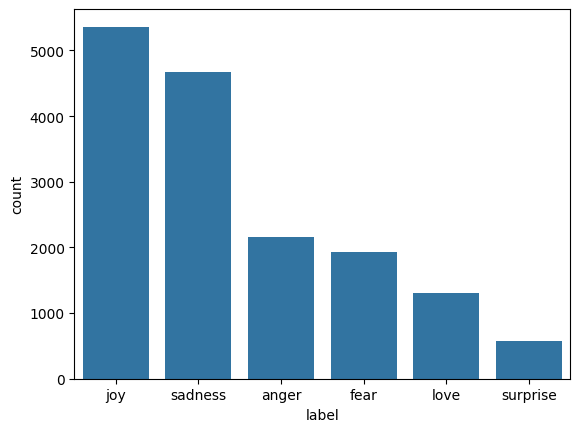

In [58]:
sns.countplot(x='label', data=df_train,order = df_train['label'].value_counts().index)


In [59]:
df_train

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
...,...,...
15995,i just had a very brief time in the beanbag an...,sadness
15996,i am now turning and i feel pathetic that i am...,sadness
15997,i feel strong and good overall,joy
15998,i feel like this was such a rude comment and i...,anger


DATA PREPROCESSING (USING NLP)

In [60]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np

max_words = 10000
max_len = 100

tokenizer = Tokenizer(
    num_words=max_words,
    oov_token="<unk>"
)

tokenizer.fit_on_texts(df_train["text"])

train_sequence = tokenizer.texts_to_sequences(df_train["text"])
test_sequence = tokenizer.texts_to_sequences(df_test["text"])

padded_train_sequence = pad_sequences(
    train_sequence,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

padded_test_sequence = pad_sequences(
    test_sequence,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

SHARED TRAINING UTILITIES

In [61]:
from sklearn.utils import class_weight

class_weight = class_weight.compute_class_weight(class_weight='balanced',classes=np.unique(train_labels),y=train_labels)

class_weight_dict = dict(enumerate(class_weight))

In [62]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

early_stopping = EarlyStopping(monitor="val_loss",patience=3,restore_best_weights=True)

## **PLAIN FOUNDATION MODELS**

MODEL 1 - SIMPLE RNN

In [63]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout, LSTM, GRU

# rnn_model = Sequential([
#     Embedding(input_dim=max_words,output_dim=128,input_length=150),
#     SimpleRNN(units=128,return_sequences=True),
#     Dropout(0.5),
#     SimpleRNN(units=64),
#     Dropout(0.5),
#     Dense(units=num_classes,activation='softmax')
# ])
# rnn_model.compile(loss='sparse_categorical_crossentropy',optimizer='adam',metrics=['accuracy'])

In [64]:
# rnn_model.fit(padded_train_sequence,train_labels,epochs=20,validation_data=(padded_test_sequence,test_labels),batch_size=32,class_weight=class_weight_dict,callbacks=[early_stopping])

# rnn_loss,rnn_acc = rnn_model.evaluate(padded_test_sequence,test_labels)
# print(f"RNN Loss: {rnn_loss}")
# print(f"RNN Accuracy: {rnn_acc}")

MODEL 2 - STANDARD LSTM

In [65]:
# lstm_model = Sequential([
#     Embedding(input_dim=max_words,output_dim=128,input_length=150),
#     LSTM(units=128,return_sequences=True),
#     Dropout(0.5),
#     LSTM(units=64),
#     Dropout(0.5),
#     Dense(units=num_classes,activation='softmax')
# ])
# lstm_model.compile(loss='sparse_categorical_crossentropy',optimizer='adam',metrics=['accuracy'])

In [66]:
# lstm_model.fit(padded_train_sequence,train_labels,epochs=20,validation_data=(padded_test_sequence,test_labels),batch_size=32,class_weight=class_weight_dict,callbacks=[early_stopping])

# lstm_loss,lstm_acc = lstm_model.evaluate(padded_test_sequence,test_labels)
# print(f"lstm Loss: {lstm_loss}")
# print(f"lstm Accuracy: {lstm_acc}")

MODEL 3 - GRU

In [67]:
# gru_model = Sequential([
#     Embedding(input_dim=max_words,output_dim=128,input_length=150),
#     GRU(units=128,return_sequences=True),
#     Dropout(0.5),
#     GRU(units=64),
#     Dropout(0.5),
#     Dense(units=num_classes,activation='softmax')
# ])
# gru_model.compile(loss='sparse_categorical_crossentropy',optimizer='adam',metrics=['accuracy'])

In [68]:
# gru_model.fit(padded_train_sequence,train_labels,epochs=20,validation_data=(padded_test_sequence,test_labels),batch_size=32,class_weight=class_weight_dict,callbacks=[early_stopping])

# gru_loss,gru_acc = gru_model.evaluate(padded_test_sequence,test_labels)
# print(f"gru Loss: {gru_loss}")
# print(f"gru Accuracy: {gru_acc}")

Advanced Bidirectional GRU

In [69]:
from tensorflow.keras.layers import Bidirectional

BiGRU = Sequential([
    Embedding(input_dim=max_words,output_dim=300,input_length=50),
    Bidirectional(GRU(128,return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(units=num_classes,activation='softmax')
    ])
BiGRU.compile(loss='sparse_categorical_crossentropy',optimizer='adam',metrics=['accuracy'])
BiGRU.summary()



/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_7 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_8 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_9 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

TRAIN & EVALUATE BIGRU MODEL

In [70]:
BiGRU.fit(padded_train_sequence,train_labels,epochs=20,validation_data=(padded_test_sequence,test_labels),batch_size=32,class_weight=class_weight_dict,callbacks=[early_stopping])

bigru_loss,bigru_acc = BiGRU.evaluate(padded_test_sequence,test_labels)
print(f"Bigru Loss: {bigru_loss}")
print(f"Bigru Accuracy: {bigru_acc}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 316s 615ms/step - accuracy: 0.6051 - loss: 0.9908 - val_accuracy: 0.8890 - val_loss: 0.3771
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 324s 619ms/step - accuracy: 0.9184 - loss: 0.2302 - val_accuracy: 0.9140 - val_loss: 0.2519
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 320s 615ms/step - accuracy: 0.9449 - loss: 0.1503 - val_accuracy: 0.9195 - val_loss: 0.1960
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 308s 616ms/step - accuracy: 0.9577 - loss: 0.1124 - val_accuracy: 0.9190 - val_loss: 0.2474
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 311s 623ms/step - accuracy: 0.9670 - loss: 0.0974 - val_accuracy: 0.9145 - val_loss: 0.2857
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 325s 627ms/step - accuracy: 0.9730 - loss: 0.0687 - val_accuracy: 0.9165 - val_loss: 0.2650
63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 119ms/step - accuracy: 0.9195 - loss: 0.1960
Bigru Loss: 0.19596950709819794
Bigru Accuracy: 0.9194999933242798


Final Model Confusion Matrices

63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 118ms/step


<Axes: >

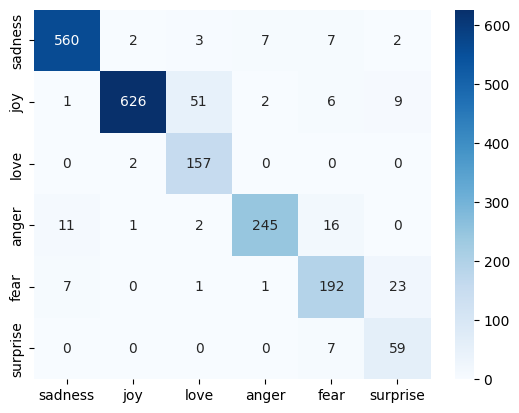

In [75]:
from sklearn.metrics import confusion_matrix, classification_report

BiGRU_pred = BiGRU.predict(padded_test_sequence)
BiGRU_pred = np.argmax(BiGRU_pred,axis=1)

sns.heatmap(confusion_matrix(test_labels,BiGRU_pred),annot=True,fmt='d',cmap='Blues',xticklabels=label_names,yticklabels=label_names)



In [76]:
print(classification_report(
    test_labels,
    BiGRU_pred,
    labels=np.arange(num_classes),
    target_names=label_names,
    zero_division=0
))

              precision    recall  f1-score   support

     sadness       0.97      0.96      0.97       581
         joy       0.99      0.90      0.94       695
        love       0.73      0.99      0.84       159
       anger       0.96      0.89      0.92       275
        fear       0.84      0.86      0.85       224
    surprise       0.63      0.89      0.74        66

    accuracy                           0.92      2000
   macro avg       0.86      0.92      0.88      2000
weighted avg       0.93      0.92      0.92      2000



Final Predictions

In [78]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]
sample_sequences = tokenizer.texts_to_sequences(sample_texts)

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
padded_sample_sequences = pad_sequences(sample_sequences,maxlen=50,padding='post',truncating='post')

sample_predictions = BiGRU.predict(padded_sample_sequences)
sample_predictions = np.argmax(sample_predictions,axis=1)

for i in range(len(sample_texts)):
    print(f"Text: {sample_texts[i]}")
    print(f"Predicted Label: {label_names[sample_predictions[i]]}")
    print()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Label: surprise

Text: I feel so alone and hopeless today.
Predicted Label: sadness

Text: I am furious that they cancelled the trip at the last minute.
Predicted Label: anger

Text: I feel terrified when walking down dark alleyways alone.
Predicted Label: fear

Text: I was shocked and completely surprised by the unexpected gift!
Predicted Label: surprise



Save Model & Tokenizer


In [83]:
import os
import pickle

model_dir = 'Models'

os.makedirs(model_dir,exist_ok=True)

BiGRU.save(os.path.join(model_dir,'BiGRU_model.keras'))

with open(os.path.join(model_dir,'tokenizer.pkl'),'wb') as file:
  pickle.dump(tokenizer,file)